## setup environment

In [1]:
# Clone the repository to bring in the database and files
!git clone https://github.com/amirreza1998/lora-medical-finetuning.git
%cd lora-medical-finetuning

# Install Colab-specific requirements
!pip install -q -r requirements_colab.txt

Cloning into 'lora-medical-finetuning'...
remote: Enumerating objects: 162, done.
remote: Counting objects: 100% (162/162), done.
remote: Compressing objects: 100% (115/115), done.
remote: Total 162 (delta 72), reused 130 (delta 43), pack-reused 0 (from 0)
Receiving objects: 100% (162/162), 1.30 MiB | 34.98 MiB/s, done.
Resolving deltas: 100% (72/72), done.
/content/lora-medical-finetuning
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.2/245.2 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 121.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 47.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 114.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 21.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not current

In [2]:
# Login to Weights & Biases for experiment tracking
# Paste your API key when prompted (get it from https://wandb.ai/authorize)
import wandb
wandb.login(key="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")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: amirrezakazemloo99 (amirrezakazemloo99-k-n-toosi-university-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## training

In [4]:
import torch
import json
import pandas as pd
from datasets import Dataset
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    TrainingArguments
)
from peft import (
    prepare_model_for_kbit_training,
    LoraConfig,
    get_peft_model,
    PeftModel,
    PeftConfig
)
from trl import SFTTrainer, DataCollatorForCompletionOnlyLM
import gc
import os
from dotenv import load_dotenv

In [5]:
# --- ABLATION STUDY PARAMETERS ---
EXPERIMENT_NAME = 'qwen2.5_lora_r32_neftune_on' # CHANGE THIS FOR EACH RUN!

class Config:
    load_dotenv()
    MODEL_NAME = "Qwen/Qwen2.5-7B-Instruct" # Or "Qwen/Qwen2.5-14B-Instruct" if you use A100
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    MAX_LENGTH = 1024 # Increased slightly to accommodate rich medical context
    OUTPUT_DIR = f'./results_{EXPERIMENT_NAME}'
    FINAL_MODEL_DIR = f'./final_model_{EXPERIMENT_NAME}'

def load_base_model():
    """Enhanced model loading with better error handling for Qwen/Llama architectures"""
    print(f"Loading base model {Config.MODEL_NAME}...")

    try:
        tokenizer = AutoTokenizer.from_pretrained(
            Config.MODEL_NAME,
            trust_remote_code=True,
            padding_side="right" # Right padding is recommended for causal LM
        )

        # Better padding configuration
        if tokenizer.pad_token is None:
            tokenizer.pad_token = tokenizer.eos_token

        # Optimized quantization config for Colab
        bnb_config = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_use_double_quant=True,
            bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.bfloat16,
            bnb_4bit_quant_storage=torch.uint8
        )

        model = AutoModelForCausalLM.from_pretrained(
            Config.MODEL_NAME,
            quantization_config=bnb_config,
            device_map="auto", # Automatically maps to A100/L4 GPU
            trust_remote_code=True,
            torch_dtype=torch.bfloat16,
            low_cpu_mem_usage=True
        )

        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
        return model, tokenizer

    except Exception as e:
        print(f"Error loading model: {e}")
        raise

In [ ]:
def prepare_training_data_enhanced(data_path: str, tokenizer, validation_split: float = 0.15):
    """Data preparation utilizing tokenizer.apply_chat_template for dynamic prompt construction"""

    print("Preparing training data...")

    with open(data_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    utterances = data.get("Utterance", [])
    formatted_data = []

    for item in utterances:
        query = item.get("query", "")
        diseases = item.get("diseases", [])

        if not query or not diseases:
            continue

        # diseases_text = "، ".join(diseases)

        # Create conversational format compatible with apply_chat_template
        messages = [
            {"role": "system", "content": " شما یک دستیار پزشکی متخصص هستید که بر اساس علائم ارائه شده، بیماری‌های محتمل را تشخیص می‌دهید. پاسخ خود را به صورت دقیق و علمی ارائه دهید. خروجی باید یک لیست با ۳ بیماری با بیشترین احتمال باشد مانند: [افسردگی اساسی,کم‌خونی,هیپوتیروئیدیسم مادرزادی]"},
            {"role": "user", "content": query},
            {"role": "assistant", "content": f"{diseases}"}
        ]

        # This will format the text exactly how the specific model (e.g. Qwen2.5) expects it!
        formatted_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
        formatted_data.append({"text": formatted_text})

    df = pd.DataFrame(formatted_data)
    dataset = Dataset.from_pandas(df)

    # Notice we don't manually tokenize and set labels=input_ids anymore.
    # TRL's SFTTrainer handles the tokenization and label masking for us!

    split_dataset = dataset.train_test_split(
        test_size=validation_split,
        seed=42,
        shuffle=True
    )

    return split_dataset

In [ ]:
def create_optimized_lora_config():
    """Optimized LoRA config using DoRA for better performance."""
    return LoraConfig(
        r=32,  # Increased rank for better capacity
        lora_alpha=64,
        lora_dropout=0.05,
        bias="none",
        task_type="CAUSAL_LM",
        target_modules=[
            "q_proj", "k_proj", "v_proj", "o_proj",
            "gate_proj", "up_proj", "down_proj"
        ],
        use_dora=True # Use Weight-Decomposed Low-Rank Adaptation (DoRA)
    )

def interactive_test(model_path: str):
    """Interactive testing interface"""
    print("Loading model for interactive testing...")

    config = PeftConfig.from_pretrained(model_path)
    tokenizer = AutoTokenizer.from_pretrained(config.base_model_name_or_path, trust_remote_code=True)

    base_model = AutoModelForCausalLM.from_pretrained(
        config.base_model_name_or_path,
        load_in_4bit=True,
        device_map="auto"
    )

    model = PeftModel.from_pretrained(base_model, model_path)
    model.eval()

    print("\n🩺 Medical assistant is ready! (Type 'exit' to quit)")

    while True:
        user_input = input("\nDescribe your symptoms (or type 'exit' to quit): ").strip()
        if user_input.lower() in ['exit', 'خروج', 'quit']: break
        if not user_input: continue

        messages = [
            {"role": "system", "content": "شما یک دستیار پزشکی متخصص هستید که بر اساس علائم ارائه شده، بیماری‌های محتمل را تشخیص می‌دهید."},
            {"role": "user", "content": user_input}
        ]

        prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024)
        inputs = {k: v.to(model.device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=256,
                temperature=0.3,
                do_sample=True,
                top_p=0.85,
                repetition_penalty=1.15,
                pad_token_id=tokenizer.eos_token_id
            )

        # Get only the generated part
        generated_ids = outputs[0][inputs['input_ids'].shape[-1]:]
        response = tokenizer.decode(generated_ids, skip_special_tokens=True)
        print(f"\n🩺 Medical Assistant response:\n{response}")


In [ ]:
print("🚀 Preparing Base Model, Tokenizer, and Dataset...")

dataset_path = "./database/intent_instruction_datasets/multi_intent_disease_queries(method3).json"

if not os.path.exists(dataset_path):
    raise FileNotFoundError(f"Dataset not found at {dataset_path}. Please upload the file and correct the path.")

model, tokenizer = load_base_model()
dataset = prepare_training_data_enhanced(dataset_path, tokenizer)
lora_config = create_optimized_lora_config()

print(f"✅ Setup completed: {len(dataset['train'])} train samples, {len(dataset['test'])} validation samples.")


In [ ]:
# ==============================================================================
# SFTTrainer Setup (Separated for Independent Training or Evaluation-Only State)
# ==============================================================================

# 1. Training Arguments (Loss logged every 5 steps, eval every 25 steps)
training_args = TrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    num_train_epochs=1,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,
    gradient_checkpointing=True,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=100,
    eval_strategy="steps",
    eval_steps=25, # Track validation loss frequently during training
    save_strategy="steps",
    save_steps=50,
    save_total_limit=3,
    fp16=False,
    bf16=True, # bfloat16 is better and fully supported on A100/L4
    dataloader_pin_memory=False,
    remove_unused_columns=True, # MUST be True so string columns are removed before collation
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    logging_steps=5, # <<< LOG LOSS EVERY 5 STEPS (as requested)
    optim="paged_adamw_8bit", # Changed to 8-bit optimizer to save VRAM
    max_grad_norm=1.0,
    weight_decay=0.05,
    neftune_noise_alpha=5.0 # NEFTune noise helps reduce overfitting and improves generation
)

# 2. Response Masking Data Collator
# Ensures the model ONLY calculates loss on the assistant's response.
response_template = "<|im_start|>assistant\n"
collator = DataCollatorForCompletionOnlyLM(response_template, tokenizer=tokenizer)

# 3. SFTTrainer Instance (Accessible independently for training OR evaluation-only)
trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    peft_config=lora_config,
    dataset_text_field="text",
    max_seq_length=Config.MAX_LENGTH,
    tokenizer=tokenizer,
    data_collator=collator, # this part makes magic masking
    packing=False
)

print("✅ SFTTrainer initialized successfully!")
print("   - trainer, training_args, and collator are now defined globally.")
print("   - You can proceed to training below, OR skip directly to evaluation!")


In [ ]:
# ==============================================================================
# Training Metrics Logger & Publication-Quality Visualization Suite
# ==============================================================================
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def save_and_plot_training_metrics(trainer, experiment_name=EXPERIMENT_NAME, output_dir=Config.OUTPUT_DIR):
    """
    Extracts all training and evaluation logs, computes academic metrics (Perplexity, EMA Loss),
    saves CSV and JSON summaries, and generates publication-ready figures (PDF & PNG @ 300 DPI).
    """
    os.makedirs(output_dir, exist_ok=True)
    history = trainer.state.log_history

    # 1. Parse Training and Evaluation Logs
    train_logs = []
    eval_logs = []

    for entry in history:
        step = entry.get("step", 0)
        epoch = entry.get("epoch", 0.0)
        if "loss" in entry:
            train_logs.append({
                "step": step,
                "epoch": epoch,
                "train_loss": entry["loss"],
                "train_perplexity": float(np.exp(min(entry["loss"], 20))), # guard against overflow
                "learning_rate": entry.get("learning_rate", None),
                "grad_norm": entry.get("grad_norm", None)
            })
        if "eval_loss" in entry:
            eval_logs.append({
                "step": step,
                "epoch": epoch,
                "eval_loss": entry["eval_loss"],
                "eval_perplexity": float(np.exp(min(entry["eval_loss"], 20)))
            })

    df_train = pd.DataFrame(train_logs)
    df_eval = pd.DataFrame(eval_logs)

    # Merge logs on step
    if not df_train.empty and not df_eval.empty:
        df_combined = pd.merge(df_train, df_eval, on=["step", "epoch"], how="outer").sort_values("step").reset_index(drop=True)
    elif not df_train.empty:
        df_combined = df_train
    else:
        df_combined = pd.DataFrame(history)

    # Add Exponential Moving Average (EMA) for smooth publication curve
    if "train_loss" in df_combined.columns and not df_combined["train_loss"].dropna().empty:
        df_combined["train_loss_ema"] = df_combined["train_loss"].ewm(span=5, adjust=False).mean()

    # 2. Save CSVs for Paper Corpus
    csv_filename = f"{experiment_name}_training_loss_history.csv"
    csv_path_local = csv_filename
    csv_path_output = os.path.join(output_dir, csv_filename)
    df_combined.to_csv(csv_path_local, index=False)
    df_combined.to_csv(csv_path_output, index=False)
    print(f"📊 Training loss history saved to: {csv_path_local} (logged every {trainer.args.logging_steps} steps)")

    # 3. Compute Summary Statistics for Paper Table
    best_eval_loss = df_combined["eval_loss"].min() if "eval_loss" in df_combined.columns and not df_combined["eval_loss"].dropna().empty else None
    best_step = int(df_combined.loc[df_combined["eval_loss"] == best_eval_loss, "step"].iloc[0]) if best_eval_loss is not None else None
    final_train_loss = df_train["train_loss"].iloc[-1] if not df_train.empty else None
    final_train_ppl = df_train["train_perplexity"].iloc[-1] if not df_train.empty else None
    peak_vram_gb = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0

    summary_stats = {
        "experiment_name": experiment_name,
        "base_model": Config.MODEL_NAME,
        "total_training_steps": int(df_combined["step"].max()) if not df_combined.empty else 0,
        "logging_interval_steps": trainer.args.logging_steps,
        "final_train_loss": round(float(final_train_loss), 4) if final_train_loss is not None else None,
        "final_train_perplexity": round(float(final_train_ppl), 4) if final_train_ppl is not None else None,
        "best_eval_loss": round(float(best_eval_loss), 4) if best_eval_loss is not None else None,
        "best_eval_perplexity": round(float(np.exp(best_eval_loss)), 4) if best_eval_loss is not None else None,
        "best_checkpoint_step": best_step,
        "peak_vram_allocated_gb": round(peak_vram_gb, 2),
        "learning_rate": trainer.args.learning_rate,
        "lr_scheduler": trainer.args.lr_scheduler_type,
        "warmup_steps": trainer.args.warmup_steps,
        "effective_batch_size": trainer.args.per_device_train_batch_size * trainer.args.gradient_accumulation_steps
    }

    # Save summary JSON
    json_path = f"{experiment_name}_paper_training_summary.json"
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(summary_stats, f, indent=4)
    print(f"📋 Paper training summary JSON saved to: {json_path}")

    # Generate LaTeX Table snippet for direct inclusion in manuscript
    latex_table = f"""% LaTeX Table for Research Paper
\\begin{{table}}[ht]
\\centering
\\caption{{Training Dynamics and Quantitative Convergence for {experiment_name}}}
\\label{{tab:training_dynamics_{experiment_name}}}
\\begin{{tabular}}{{lc}}
\\hline
\\textbf{{Metric / Hyperparameter}} & \\textbf{{Value}} \\\\
\\hline
Base Model & {summary_stats['base_model']} \\\\
LoRA Rank ($r$) & 32 \\\\
Effective Batch Size & {summary_stats['effective_batch_size']} \\\\
Optimizer & 8-bit Paged AdamW \\\\
Learning Rate / Schedule & {summary_stats['learning_rate']} ({summary_stats['lr_scheduler']}) \\\\
Total Training Steps & {summary_stats['total_training_steps']} \\\\
Final Training Loss & {summary_stats['final_train_loss']} \\\\
Best Validation Loss & {summary_stats['best_eval_loss']} \\\\
Final Train Perplexity (PPL) & {summary_stats['final_train_perplexity']} \\\\
Best Validation PPL & {summary_stats['best_eval_perplexity']} \\\\
Peak VRAM Allocated & {summary_stats['peak_vram_allocated_gb']} GB \\\\
\\hline
\\end{{tabular}}
\\end{{table}}
"""
    tex_path = f"{experiment_name}_latex_table.tex"
    with open(tex_path, "w", encoding="utf-8") as f:
        f.write(latex_table)
    print(f"📑 LaTeX table snippet saved to: {tex_path}")

    # 4. Publication-Ready 4-Panel Figure (PDF & PNG @ 300 DPI)
    sns.set_theme(style="whitegrid", font="sans-serif")
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)

    # Panel (a): Loss Dynamics (Every 5 steps + smoothed trend + eval loss)
    ax1 = axes[0, 0]
    if not df_train.empty:
        ax1.plot(df_train["step"], df_train["train_loss"], color="#4A90E2", alpha=0.35, linewidth=1.5, label=f"Train Loss (Every {trainer.args.logging_steps} steps)")
        if "train_loss_ema" in df_combined.columns:
            train_ema = df_combined.dropna(subset=["train_loss_ema"])
            ax1.plot(train_ema["step"], train_ema["train_loss_ema"], color="#1B5E20", linewidth=2.2, label="Train Loss (EMA Trend)")
    if not df_eval.empty:
        ax1.plot(df_eval["step"], df_eval["eval_loss"], color="#D32F2F", marker="o", markersize=6, linewidth=2.2, label="Validation Loss")
    ax1.set_title("(a) Training & Validation Loss Dynamics", fontsize=13, fontweight="bold", pad=8)
    ax1.set_xlabel("Optimization Steps", fontsize=11)
    ax1.set_ylabel("Cross-Entropy Loss", fontsize=11)
    ax1.legend(loc="upper right", frameon=True, fontsize=10)
    ax1.grid(True, linestyle="--", alpha=0.5)

    # Panel (b): Language Model Perplexity (PPL)
    ax2 = axes[0, 1]
    if not df_train.empty:
        ax2.plot(df_train["step"], df_train["train_perplexity"], color="#E65100", linewidth=1.8, label="Train Perplexity ($e^{\\mathcal{L}_{train}}$)")
    if not df_eval.empty:
        ax2.plot(df_eval["step"], df_eval["eval_perplexity"], color="#7B1FA2", marker="s", markersize=6, linewidth=2.0, label="Validation Perplexity ($e^{\\mathcal{L}_{val}}$)")
    ax2.set_title("(b) Perplexity Trajectory (Domain Adaptation)", fontsize=13, fontweight="bold", pad=8)
    ax2.set_xlabel("Optimization Steps", fontsize=11)
    ax2.set_ylabel("Perplexity (PPL)", fontsize=11)
    ax2.legend(loc="upper right", frameon=True, fontsize=10)
    ax2.grid(True, linestyle="--", alpha=0.5)

    # Panel (c): Learning Rate Schedule
    ax3 = axes[1, 0]
    lr_data = df_train.dropna(subset=["learning_rate"])
    if not lr_data.empty:
        ax3.plot(lr_data["step"], lr_data["learning_rate"], color="#00838F", linewidth=2.0, label="Cosine Decay with Warmup")
    ax3.set_title("(c) Learning Rate Schedule", fontsize=13, fontweight="bold", pad=8)
    ax3.set_xlabel("Optimization Steps", fontsize=11)
    ax3.set_ylabel("Learning Rate", fontsize=11)
    ax3.ticklabel_format(style="sci", axis="y", scilimits=(0, 0))
    ax3.legend(loc="upper right", frameon=True, fontsize=10)
    ax3.grid(True, linestyle="--", alpha=0.5)

    # Panel (d): Gradient Norm (Stability & Clipping)
    ax4 = axes[1, 1]
    grad_data = df_train.dropna(subset=["grad_norm"])
    if not grad_data.empty:
        ax4.plot(grad_data["step"], grad_data["grad_norm"], color="#455A64", alpha=0.75, linewidth=1.5, label="Gradient Norm ($||\\mathbf{g}||_2$)")
        ax4.axhline(y=trainer.args.max_grad_norm, color="#C62828", linestyle=":", linewidth=1.5, label=f"Max Grad Norm Clip ({trainer.args.max_grad_norm})")
    ax4.set_title("(d) Gradient Norm & Optimization Stability", fontsize=13, fontweight="bold", pad=8)
    ax4.set_xlabel("Optimization Steps", fontsize=11)
    ax4.set_ylabel("L2 Gradient Norm", fontsize=11)
    ax4.legend(loc="upper right", frameon=True, fontsize=10)
    ax4.grid(True, linestyle="--", alpha=0.5)

    plt.suptitle(f"Training Convergence & Dynamics: {experiment_name}", fontsize=15, fontweight="bold", y=0.995)
    plt.tight_layout()

    # Save both vector PDF (for LaTeX papers) and 300 DPI PNG
    pdf_fig = f"{experiment_name}_loss_curve.pdf"
    png_fig = f"{experiment_name}_loss_curve.png"
    plt.savefig(pdf_fig, dpi=300, bbox_inches="tight")
    plt.savefig(png_fig, dpi=300, bbox_inches="tight")
    if output_dir and output_dir != "./":
        plt.savefig(os.path.join(output_dir, pdf_fig), dpi=300, bbox_inches="tight")
        plt.savefig(os.path.join(output_dir, png_fig), dpi=300, bbox_inches="tight")
    plt.show()

    print(f"📈 Publication-quality figures saved:")
    print(f"  - Vector PDF (LaTeX): {pdf_fig}")
    print(f"  - High-Res PNG (300 DPI): {png_fig}")

    return df_combined, summary_stats


In [ ]:
# ==============================================================================
# Train Model Cell
# NOTE: If you are in EVALUATION ONLY mode, SKIP this cell!
# ==============================================================================
def train_model(trainer, tokenizer):
    """Executes SFT training, saves final checkpoint, and generates publication artifacts."""
    print("Clearing GPU memory before training...")
    torch.cuda.empty_cache()
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    print("🚀 Starting training... (Loss reported every 5 steps)")
    start_time = time.time()

    training_result = trainer.train()

    elapsed = time.time() - start_time
    print(f"✅ Training completed in {elapsed:.1f}s ({elapsed/60:.2f} mins)!")
    print(f"Final Training Loss: {training_result.training_loss:.4f}")

    # Save model and tokenizer
    trainer.model.save_pretrained(Config.FINAL_MODEL_DIR, safe_serialization=True)
    tokenizer.save_pretrained(Config.FINAL_MODEL_DIR)
    print(f"💾 Checkpoint saved to: {Config.FINAL_MODEL_DIR}")

    # Plot loss and extract paper corpus data
    df_history, paper_summary = save_and_plot_training_metrics(trainer, EXPERIMENT_NAME, Config.OUTPUT_DIR)

    return trainer.model

# Execute Training (Comment out if running in Evaluation-Only mode)
trained_model = train_model(trainer, tokenizer)


In [ ]:
# ==============================================================================
# EVALUATION ONLY / CHECKPOINT LOADER
# Use this block if you want to evaluate an already trained checkpoint without training!
# ==============================================================================
def load_checkpoint_for_evaluation(model_dir=Config.FINAL_MODEL_DIR):
    """Attaches a saved LoRA adapter onto the base model for standalone evaluation."""
    print(f"Loading LoRA adapter checkpoint from {model_dir}...")
    eval_model = PeftModel.from_pretrained(model, model_dir)
    eval_model.eval()
    # Attach to trainer so subsequent evaluate_and_plot calls work seamlessly
    trainer.model = eval_model
    print("✅ Model loaded and set to evaluation mode!")
    return eval_model

# To evaluate an existing model without retraining, uncomment and run:
# load_checkpoint_for_evaluation(Config.FINAL_MODEL_DIR)


### save the model in the google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r /content/lora-medical-finetuning /content/drive/MyDrive

# test the result

In [ ]:
# Automatically install required evaluation libraries
try:
    import evaluate
except ImportError:
    !pip install -q evaluate rouge_score
    import evaluate

import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

def evaluate_and_plot(trainer, tokenizer, dataset, experiment_name, num_samples=50):
    print(f"Evaluating {experiment_name} on {num_samples} test samples...")
    rouge = evaluate.load('rouge')

    # Random test subset
    test_data = dataset['test'].shuffle(seed=42).select(range(min(num_samples, len(dataset['test']))))

    predictions = []
    references = []

    model = trainer.model
    model.eval()

    for item in tqdm(test_data):
        text = item['text']
        prompt_end = text.find("<|im_start|>assistant\n") + len("<|im_start|>assistant\n")
        prompt = text[:prompt_end]
        actual_response = text[prompt_end:].replace("<|im_end|>", "").strip()

        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024)
        inputs = {k: v.to(model.device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=128,
                temperature=0.1,
                do_sample=True,
                pad_token_id=tokenizer.eos_token_id
            )

        generated_ids = outputs[0][inputs['input_ids'].shape[-1]:]
        generated_response = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()

        predictions.append(generated_response)
        references.append(actual_response)

    # Calculate ROUGE scores
    results = rouge.compute(predictions=predictions, references=references)

    # Plot Evaluation
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(8, 5))
    metrics = ['rouge1', 'rouge2', 'rougeL']
    scores = [results[m] * 100 for m in metrics]
    ax = sns.barplot(x=metrics, y=scores, palette="viridis")
    plt.title(f'ROUGE Scores: {experiment_name}', fontsize=16, fontweight='bold')
    plt.ylabel('Score (%)', fontsize=12)
    plt.ylim(0, 100)
    for i, v in enumerate(scores):
        ax.text(i, v + 1.5, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{experiment_name}_rouge_metrics.pdf', dpi=300)
    plt.show()

    # Plot Training Loss History
    plt.figure(figsize=(10, 6))
    history = trainer.state.log_history
    train_steps = [x['step'] for x in history if 'loss' in x]
    train_loss = [x['loss'] for x in history if 'loss' in x]
    eval_steps = [x['step'] for x in history if 'eval_loss' in x]
    eval_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]

    plt.plot(train_steps, train_loss, label='Training Loss', color='blue', alpha=0.7, linewidth=2)
    if eval_loss:
        plt.plot(eval_steps, eval_loss, label='Validation Loss', color='red', marker='o', linewidth=2)
    plt.title(f'Loss Curve: {experiment_name}', fontsize=16, fontweight='bold')
    plt.xlabel('Training Steps', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{experiment_name}_loss_curve.pdf', dpi=300)
    plt.show()

    # Save Qualitative Results
    df_results = pd.DataFrame({
        "Ground Truth": references,
        "Model Prediction": predictions
    })
    df_results.to_csv(f"{experiment_name}_qualitative.csv", index=False, encoding="utf-8-sig")

    print(f"✅ Ablation study files saved for {experiment_name}:")
    print(f"  - {experiment_name}_rouge_metrics.pdf")
    print(f"  - {experiment_name}_loss_curve.pdf")
    print(f"  - {experiment_name}_qualitative.csv")

    return results

# if __name__ == "__main__":
# Ensure this runs only if trainer is available (so we don't crash the nb logic if someone just runs all cells blindly)
# try:
if 'trainer' in globals() and 'EXPERIMENT_NAME' in globals():
    evaluate_and_plot(trainer, tokenizer, dataset, EXPERIMENT_NAME)
# except Exception as e:
#     pass

### Force GPU Execution for Model and Evaluation

In [ ]:
import os
import torch
import gc
from peft import PeftModel, PeftConfig
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

# 1. Clear GPU memory completely first
for var in ['model', 'base_model', 'model_peft']:
    if var in globals():
        del globals()[var]
torch.cuda.empty_cache()
gc.collect()

# 2. Re-load the model dynamically using Config.FINAL_MODEL_DIR
model_path = (
    Config.FINAL_MODEL_DIR if 'Config' in globals() and os.path.exists(Config.FINAL_MODEL_DIR)
    else f"./final_model_{EXPERIMENT_NAME}" if 'EXPERIMENT_NAME' in globals() and os.path.exists(f"./final_model_{EXPERIMENT_NAME}")
    else "/content/lora-medical-finetuning/final_model_qwen2.5_lora_r32_neftune_on"
)

print(f"Loading config & tokenizer from {model_path}...")
config = PeftConfig.from_pretrained(model_path)
tokenizer = AutoTokenizer.from_pretrained(config.base_model_name_or_path, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("Loading Base Model in 4-bit with strict GPU mapping...")
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)

# Force device_map to use device 0 instead of "auto" to avoid any CPU offloading
gpu_device_map = {"": 0}

base_model = AutoModelForCausalLM.from_pretrained(
    config.base_model_name_or_path,
    quantization_config=bnb_config,
    device_map=gpu_device_map,
    trust_remote_code=True,
    torch_dtype=torch.bfloat16
)

print("Loading LoRA adapters onto GPU...")
model_peft = PeftModel.from_pretrained(base_model, model_path, device_map=gpu_device_map)
model_peft.eval()

# 3. Update trainer to point to the strict GPU model
# Since trainer is defined outside, we update trainer.model directly.
# If running in a fresh session where trainer wasn't instantiated, create a lightweight wrapper.
if 'trainer' in globals() and trainer is not None:
    trainer.model = model_peft
else:
    class MockTrainer:
        def __init__(self, m):
            self.model = m
            self.state = type("State", (), {"log_history": []})()
    trainer = MockTrainer(model_peft)

print("\n✅ Success! Model loaded entirely on GPU and attached to trainer. Now try running the test_single_generation cell below.")


Loading config & tokenizer...
Loading Base Model in 4-bit with strict GPU mapping...


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Loading LoRA adapters onto GPU...

✅ Success! Model loaded entirely on GPU. Now try running the test_single_generation cell above.


### Test Generation on a Single Sample with Verbose Memory Tracking

In [ ]:
import torch
import time

def test_single_generation(model, tokenizer, dataset):
    # Print current GPU Memory allocation
    if torch.cuda.is_available():
        print(f"Initial GPU Allocated Memory: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
        print(f"Initial GPU Cached Memory: {torch.cuda.memory_reserved() / 1e9:.2f} GB")

    # Pick 1 sample
    sample = dataset['test'][0]
    text = sample['text']
    prompt_end = text.find("<|im_start|>assistant\n") + len("<|im_start|>assistant\n")
    prompt = text[:prompt_end]

    print("\n--- Prompt ---")
    print(prompt)
    print("---------------\n")

    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    print("Generating response (timing started)... ")
    start_time = time.time()

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=64, # reduced to speed up testing
            temperature=0.1,
            do_sample=True,
            pad_token_id=tokenizer.eos_token_id
        )

    end_time = time.time()
    print(f"Generation completed in {end_time - start_time:.2f} seconds!")

    generated_ids = outputs[0][inputs['input_ids'].shape[-1]:]
    response = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()

    print("\n--- Model Output ---")
    print(response)
    print("--------------------")

test_single_generation(trainer.model, tokenizer, dataset)

Initial GPU Allocated Memory: 5.95 GB
Initial GPU Cached Memory: 6.55 GB

--- Prompt ---
<|im_start|>system
شما یک دستیار پزشکی متخصص هستید که بر اساس علائم ارائه شده، بیماری‌های محتمل را تشخیص می‌دهید. پاسخ خود را به صورت دقیق و علمی ارائه دهید.<|im_end|>
<|im_start|>user
حرکات غیرارادی تو پاهام دارم و نمی‌تونم درست بخوابم، در کنارش قلبم تند می‌زنه و سرگیجه دارم.<|im_end|>
<|im_start|>assistant

---------------

Generating response (timing started)... 
Generation completed in 97.85 seconds!

--- Model Output ---
با توجه به علائم ذکر شده، بیماری‌های محتمل عبارتند از: سندرم پای بی‌قرار، پرفشاری خون، دیسک کمر

برای تشخیص دقیق‌
--------------------


### plot

In [ ]:
# Automatically install required evaluation libraries
try:
    import evaluate
except ImportError:
    !pip install -q evaluate rouge_score
    import evaluate

import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

def evaluate_and_plot(trainer, tokenizer, dataset, experiment_name, num_samples=50):
    print(f"Evaluating {experiment_name} on {num_samples} test samples...")
    rouge = evaluate.load('rouge')

    # Random test subset
    test_data = dataset['test'].shuffle(seed=42).select(range(min(num_samples, len(dataset['test']))))

    predictions = []
    references = []

    model = trainer.model
    model.eval()

    for item in tqdm(test_data):
        text = item['text']
# import pdb;pdb.set_trace()
        prompt_end = text.find("<|im_start|>assistant\n") + len("<|im_start|>assistant\n")
        prompt = text[:prompt_end]
        actual_response = text[prompt_end:].replace("<|im_end|>", "").strip()

        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024)
        inputs = {k: v.to(model.device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=128,
                temperature=0.1,
                do_sample=True,
                pad_token_id=tokenizer.eos_token_id
            )

        generated_ids = outputs[0][inputs['input_ids'].shape[-1]:]
        generated_response = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()

        predictions.append(generated_response)
        references.append(actual_response)

    # Calculate ROUGE scores
    results = rouge.compute(predictions=predictions, references=references)

    # Plot Evaluation
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(8, 5))
    metrics = ['rouge1', 'rouge2', 'rougeL']
    scores = [results[m] * 100 for m in metrics]
    ax = sns.barplot(x=metrics, y=scores, palette="viridis")
    plt.title(f'ROUGE Scores: {experiment_name}', fontsize=16, fontweight='bold')
    plt.ylabel('Score (%)', fontsize=12)
    plt.ylim(0, 100)
    for i, v in enumerate(scores):
        ax.text(i, v + 1.5, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{experiment_name}_rouge_metrics.pdf', dpi=300)
    plt.show()

    # Plot Training Loss History
    plt.figure(figsize=(10, 6))
    history = trainer.state.log_history
    train_steps = [x['step'] for x in history if 'loss' in x]
    train_loss = [x['loss'] for x in history if 'loss' in x]
    eval_steps = [x['step'] for x in history if 'eval_loss' in x]
    eval_loss = [x['eval_loss'] for x in history if 'eval_loss' in x]

    plt.plot(train_steps, train_loss, label='Training Loss', color='blue', alpha=0.7, linewidth=2)
    if eval_loss:
        plt.plot(eval_steps, eval_loss, label='Validation Loss', color='red', marker='o', linewidth=2)
    plt.title(f'Loss Curve: {experiment_name}', fontsize=16, fontweight='bold')
    plt.xlabel('Training Steps', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{experiment_name}_loss_curve.pdf', dpi=300)
    plt.show()

    # Save Qualitative Results
    df_results = pd.DataFrame({
        "Ground Truth": references,
        "Model Prediction": predictions
    })
    df_results.to_csv(f"{experiment_name}_qualitative.csv", index=False, encoding="utf-8-sig")

    print(f"✅ Ablation study files saved for {experiment_name}:")
    print(f"  - {experiment_name}_rouge_metrics.pdf")
    print(f"  - {experiment_name}_loss_curve.pdf")
    print(f"  - {experiment_name}_qualitative.csv")

    return results

if 'trainer' in globals() and 'EXPERIMENT_NAME' in globals():
    print("\n--- Starting Generation & Evaluation ---")
    # Running with 5 samples for speed (approx 5-7 minutes). Change to 50 for full eval.
    final_results = evaluate_and_plot(trainer, tokenizer, dataset, EXPERIMENT_NAME, num_samples=5)
    print("\nFinal ROUGE Scores:", final_results)


--- Starting Generation & Evaluation ---
Evaluating qwen2.5_lora_r32_neftune_on on 5 test samples...


  0%|          | 0/5 [00:00<?, ?it/s]

> /tmp/ipykernel_994/3966951981.py(29)evaluate_and_plot()
     27     for item in tqdm(test_data):
     28         text = item['text']
---> 29         import pdb;pdb.set_trace()
     30         prompt_end = text.find("<|im_start|>assistant\n") + len("<|im_start|>assistant\n")
     31         prompt = text[:prompt_end]

'<|im_start|>system\nشما یک دستیار پزشکی متخصص هستید که بر اساس علائم ارائه شده، بیماری\u200cهای محتمل را تشخیص می\u200cدهید. پاسخ خود را به صورت دقیق و علمی ارائه دهید.<|im_end|>\n<|im_start|>user\nیه برآمدگی تو شکمم حس می\u200cکنم و با سرفه بزرگ\u200cتر می\u200cشه، در کنارش سرفه\u200cهای شدید دارم و نفس کشیدن برام سخت شده.<|im_end|>\n<|im_start|>assistant\nبا توجه به علائم ذکر شده، بیماری\u200cهای محتمل عبارتند از: فتق، بیماری مزمن انسدادی ریه، دیورتیکولیت\n\nبرای تشخیص دقیق\u200cتر، توصیه می\u200cشود با پزشک متخصص مشورت کنید و آزمایش\u200cهای لازم را انجام دهید.<|im_end|>\n'
> /tmp/ipykernel_994/3966951981.py(30)evaluate_and_plot()
     28         text = item['text']


  0%|          | 0/5 [20:09<?, ?it/s]

--KeyboardInterrupt--

KeyboardInterrupt: Interrupted by user


KeyboardInterrupt: 

### Targeted Evaluation


Evaluating qwen2.5_lora_r32_neftune_on on 5 test samples...


100%|██████████| 5/5 [13:43<00:00, 164.73s/it]
/tmp/ipykernel_994/2852094793.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=metrics, y=scores, palette="viridis")


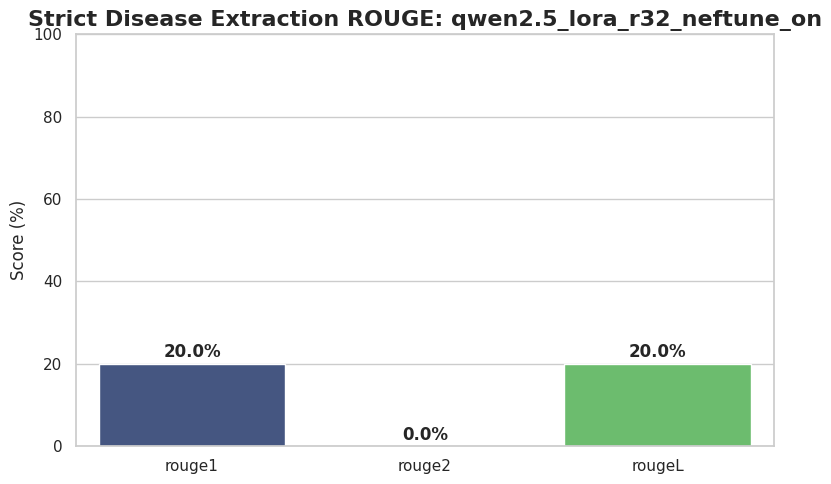

✅ Ablation files saved for qwen2.5_lora_r32_neftune_on!


{'rouge1': np.float64(0.2),
 'rouge2': np.float64(0.0),
 'rougeL': np.float64(0.2),
 'rougeLsum': np.float64(0.2)}

In [ ]:
import torch
import evaluate
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

def extract_diseases(text):
    """Strips the boilerplate text and returns only the predicted diseases."""
    start_marker = "بیماری‌های محتمل عبارتند از:"
    end_marker = "\n\nبرای تشخیص"

    try:
        # Find where the diseases start and end
        start_idx = text.find(start_marker) + len(start_marker)
        end_idx = text.find(end_marker)

        if text.find(start_marker) == -1: return text.strip() # Fallback if model hallucinates

        if end_idx == -1: return text[start_idx:].strip() # Fallback if model forgets the ending

        return text[start_idx:end_idx].strip()
    except Exception:
        return text.strip()

def evaluate_and_plot(trainer, tokenizer, dataset, experiment_name, num_samples=50):
    print(f"Evaluating {experiment_name} on {num_samples} test samples...")
    rouge = evaluate.load('rouge')

    test_data = dataset['test'].shuffle(seed=42).select(range(min(num_samples, len(dataset['test']))))

    predictions_full = []
    references_full = []

    predictions_diseases_only = []
    references_diseases_only = []

    model = trainer.model
    model.eval()

    for item in tqdm(test_data):
        text = item['text']
        prompt_end = text.find("<|im_start|>assistant\n") + len("<|im_start|>assistant\n")
        prompt = text[:prompt_end]
        actual_response = text[prompt_end:].replace("<|im_end|>", "").strip()

        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024)
        inputs = {k: v.to(model.device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=128,
                temperature=0.1,
                do_sample=True,
                pad_token_id=tokenizer.eos_token_id
            )

        generated_ids = outputs[0][inputs['input_ids'].shape[-1]:]
        generated_response = tokenizer.decode(generated_ids, skip_special_tokens=True).strip()

        # Save full strings for the CSV
        predictions_full.append(generated_response)
        references_full.append(actual_response)

        # Extract JUST the diseases for strict evaluation
        predictions_diseases_only.append(extract_diseases(generated_response))
        references_diseases_only.append(extract_diseases(actual_response))

    # Calculate ROUGE strictly on the diseases
    results = rouge.compute(predictions=predictions_diseases_only, references=references_diseases_only)

    # Plot Evaluation
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(8, 5))
    metrics = ['rouge1', 'rouge2', 'rougeL']
    scores = [results[m] * 100 for m in metrics]
    ax = sns.barplot(x=metrics, y=scores, palette="viridis")
    plt.title(f'Strict Disease Extraction ROUGE: {experiment_name}', fontsize=16, fontweight='bold')
    plt.ylabel('Score (%)', fontsize=12)
    plt.ylim(0, 100)
    for i, v in enumerate(scores):
        ax.text(i, v + 1.5, f"{v:.1f}%", ha='center', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{experiment_name}_rouge_metrics.pdf', dpi=300)
    plt.show()

    # Save Qualitative Results (Showing what was extracted)
    df_results = pd.DataFrame({
        "Ground Truth Diseases": references_diseases_only,
        "Predicted Diseases": predictions_diseases_only,
        "Full Generated Text": predictions_full
    })
    df_results.to_csv(f"{experiment_name}_qualitative.csv", index=False, encoding="utf-8-sig")

    print(f"✅ Ablation files saved for {experiment_name}!")

    return results

# Run the strict evaluation!
evaluate_and_plot(trainer, tokenizer, dataset, EXPERIMENT_NAME, num_samples=5)


In [ ]:
cp -r /content/lora-medical-finetuning /content/drive/MyDrive